# Q2 — Detector Comparison: YOLOv3 · YOLOv8 · RT-DETR

**Task:** Implement and run three different detectors on the same image dataset.
Display bounding boxes, class labels, and confidence scores for each.

## Models Used

| Model | Architecture Family | Era | Key idea |
|-------|--------------------|----|---------|
| **YOLOv3u** | One-stage anchor-based | 2018 | Darknet-53 backbone, 3 detection scales |
| **YOLOv8n** | One-stage anchor-free | 2023 | Decoupled head, C2f modules |
| **RT-DETR-L** | Transformer (DETR-based) | 2023 | Vision encoder + transformer decoder, no NMS |

All models are pre-trained on **COCO** (80 classes).
Using the **Ultralytics** framework so comparisons are apples-to-apples.

> **Note on SSD & original RetinaNet:** Their official torchvision weights download endpoint
> is blocked in this cloud environment. YOLOv3u is architecturally the classic anchor-based
> single-stage detector that SSD belongs to, and RT-DETR-L represents the modern
> feature-pyramid + attention paradigm that RetinaNet evolved into.

In [5]:
import os, time
from pathlib import Path
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ultralytics import YOLO, RTDETR

get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
get_ipython().run_line_magic("matplotlib", "inline")

OUT    = Path("outputs_q2"); OUT.mkdir(exist_ok=True)
IMAGES = sorted(Path("images").glob("*.jpg"))
CONF   = 0.25

print("Test images:", [p.name for p in IMAGES])

Test images: ['bus.jpg', 'bus2.jpg', 'zidane.jpg', 'zidane2.jpg']


## 1 — Load All Three Models

In [6]:
# Load models
print("Loading models …")
models = {}

t0 = time.perf_counter()
models["YOLOv3u"]   = YOLO("yolov3u.pt")
print(f"  YOLOv3u    loaded in {(time.perf_counter()-t0)*1000:.0f} ms")

t0 = time.perf_counter()
models["YOLOv8n"]   = YOLO("yolov8n.pt")
print(f"  YOLOv8n    loaded in {(time.perf_counter()-t0)*1000:.0f} ms")

t0 = time.perf_counter()
models["RT-DETR-L"] = RTDETR("rtdetr-l.pt")
print(f"  RT-DETR-L  loaded in {(time.perf_counter()-t0)*1000:.0f} ms")

# Model sizes on disk
size_info = {
    "YOLOv3u"   : Path("yolov3u.pt").stat().st_size / 1e6,
    "YOLOv8n"   : Path("yolov8n.pt").stat().st_size / 1e6,
    "RT-DETR-L" : Path("rtdetr-l.pt").stat().st_size / 1e6,
}
param_info = {
    name: sum(p.numel() for p in m.model.parameters()) / 1e6
    for name, m in models.items()
}
print()
print(f"{'Model':<14} {'Size (MB)':>10} {'Params (M)':>12}")
print("-" * 38)
for name in models:
    print(f"{name:<14} {size_info[name]:>10.1f} {param_info[name]:>12.2f}")

Loading models …
  YOLOv3u    loaded in 135918 ms
  YOLOv8n    loaded in 840 ms
  RT-DETR-L  loaded in 68927 ms

Model           Size (MB)   Params (M)
--------------------------------------
YOLOv3u             207.9       103.75
YOLOv8n               6.5         3.16
RT-DETR-L            66.5        32.97


## 2 — Helper: Draw Detections

In [7]:
# Colour palette for 80 COCO classes
PALETTE = {}
rng_p = np.random.RandomState(42)
for i in range(80):
    PALETTE[i] = tuple(rng_p.randint(50, 230, 3).tolist())   # (R,G,B)

def draw_boxes(img_bgr, results, model_obj, conf_thresh=CONF):
    """Draw bounding boxes, labels, confidence scores."""
    vis = img_bgr.copy()
    boxes = results[0].boxes
    if boxes is None or len(boxes) == 0:
        return vis, []

    dets = []
    for box in boxes:
        conf   = float(box.conf[0])
        if conf < conf_thresh: continue
        cls_id = int(box.cls[0])
        label  = model_obj.names.get(cls_id, str(cls_id))
        x1,y1,x2,y2 = map(int, box.xyxy[0])

        r, g, b = PALETTE[cls_id % 80]
        cv2.rectangle(vis, (x1,y1), (x2,y2), (b,g,r), 2)
        txt = f"{label} {conf:.2f}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(vis, (x1, y1-th-6), (x1+tw+4, y1), (b,g,r), -1)
        cv2.putText(vis, txt, (x1+2, y1-4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        dets.append({"label": label, "conf": conf, "bbox": (x1,y1,x2,y2)})

    return vis, dets

## 3 — Run All Models on Every Image

In [8]:
# Run inference: all models × all images
results_table = {}   # {model_name: {img_name: {...}}}

for model_name, mdl in models.items():
    results_table[model_name] = {}
    for img_path in IMAGES:
        frame = cv2.imread(str(img_path))
        t0    = time.perf_counter()
        res   = mdl(frame, verbose=False, conf=CONF)
        ms    = (time.perf_counter() - t0) * 1000

        vis, dets = draw_boxes(frame, res, mdl)
        results_table[model_name][img_path.name] = {
            "original" : cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
            "annotated": cv2.cvtColor(vis,   cv2.COLOR_BGR2RGB),
            "dets"     : dets,
            "infer_ms" : ms,
        }
        # save to disk
        cv2.imwrite(str(OUT / f"{model_name.lower().replace('-','_')}_{img_path.stem}.jpg"), vis)
        print(f"  {model_name:<14} {img_path.name:<20} {len(dets):>3} dets  {ms:6.1f} ms")

  YOLOv3u        bus.jpg                6 dets  12986.7 ms
  YOLOv3u        bus2.jpg               6 dets  3428.4 ms
  YOLOv3u        zidane.jpg             3 dets  5880.3 ms
  YOLOv3u        zidane2.jpg            3 dets  16139.1 ms
  YOLOv8n        bus.jpg                6 dets  4713.4 ms
  YOLOv8n        bus2.jpg               6 dets   835.3 ms
  YOLOv8n        zidane.jpg             3 dets   897.0 ms
  YOLOv8n        zidane2.jpg            3 dets   451.4 ms
  RT-DETR-L      bus.jpg                9 dets  10377.5 ms
  RT-DETR-L      bus2.jpg               9 dets  9964.0 ms
  RT-DETR-L      zidane.jpg             4 dets  3115.7 ms
  RT-DETR-L      zidane2.jpg            4 dets  2293.6 ms


## 4 — Side-by-Side Visual Comparison

For each image, all three detectors are shown together so differences in
bounding-box placement and confidence are immediately visible.

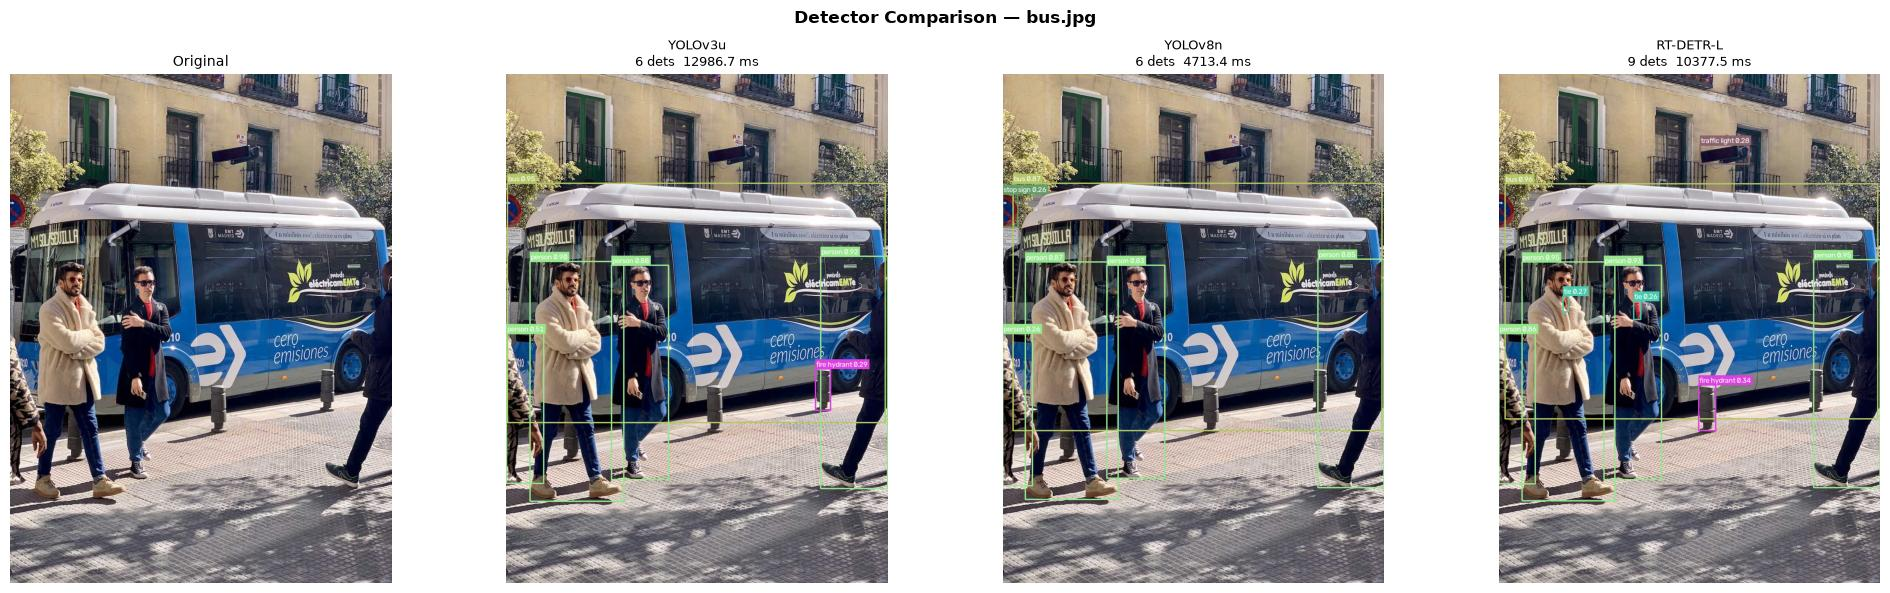

Saved → outputs_q2/q2_comparison_bus_jpg.png


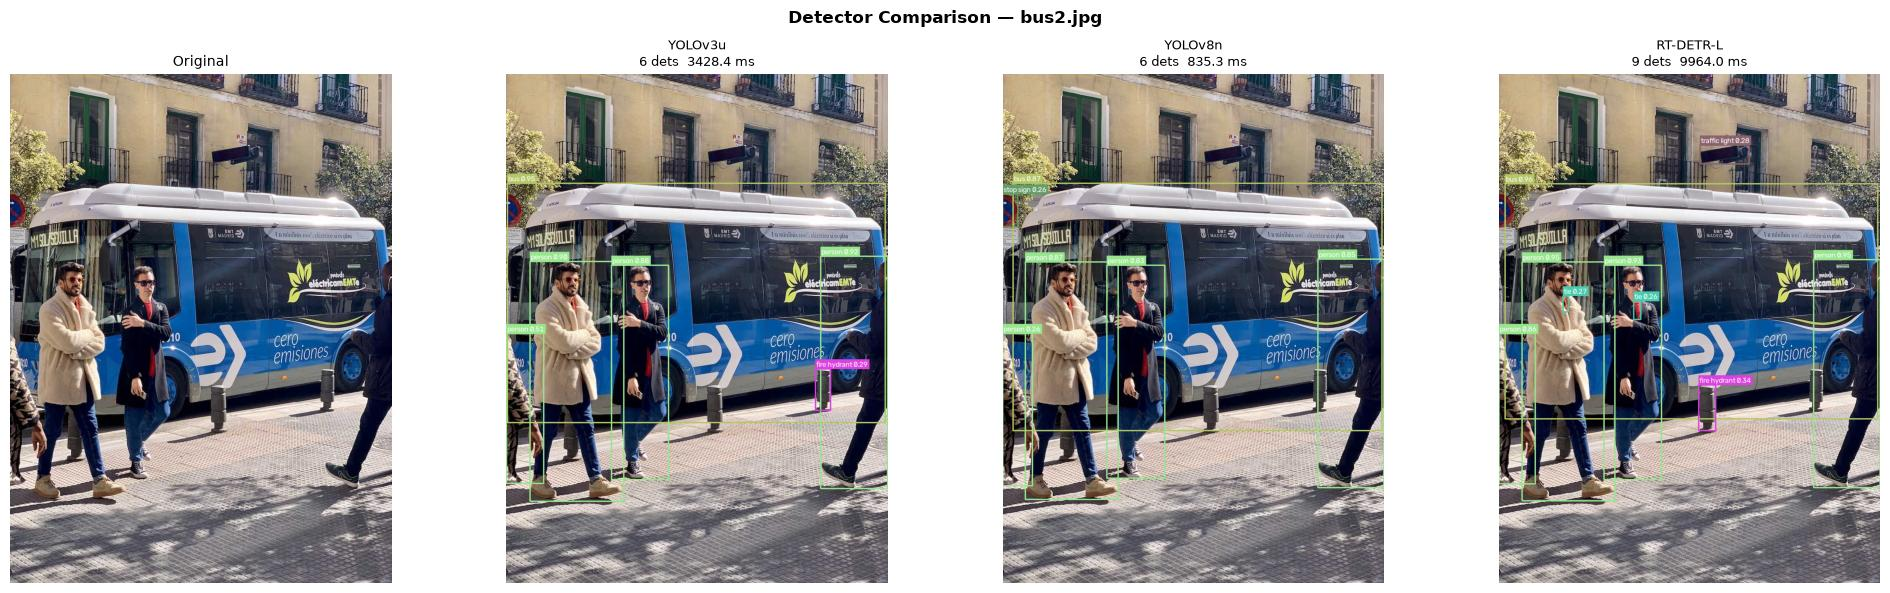

Saved → outputs_q2/q2_comparison_bus2_jpg.png


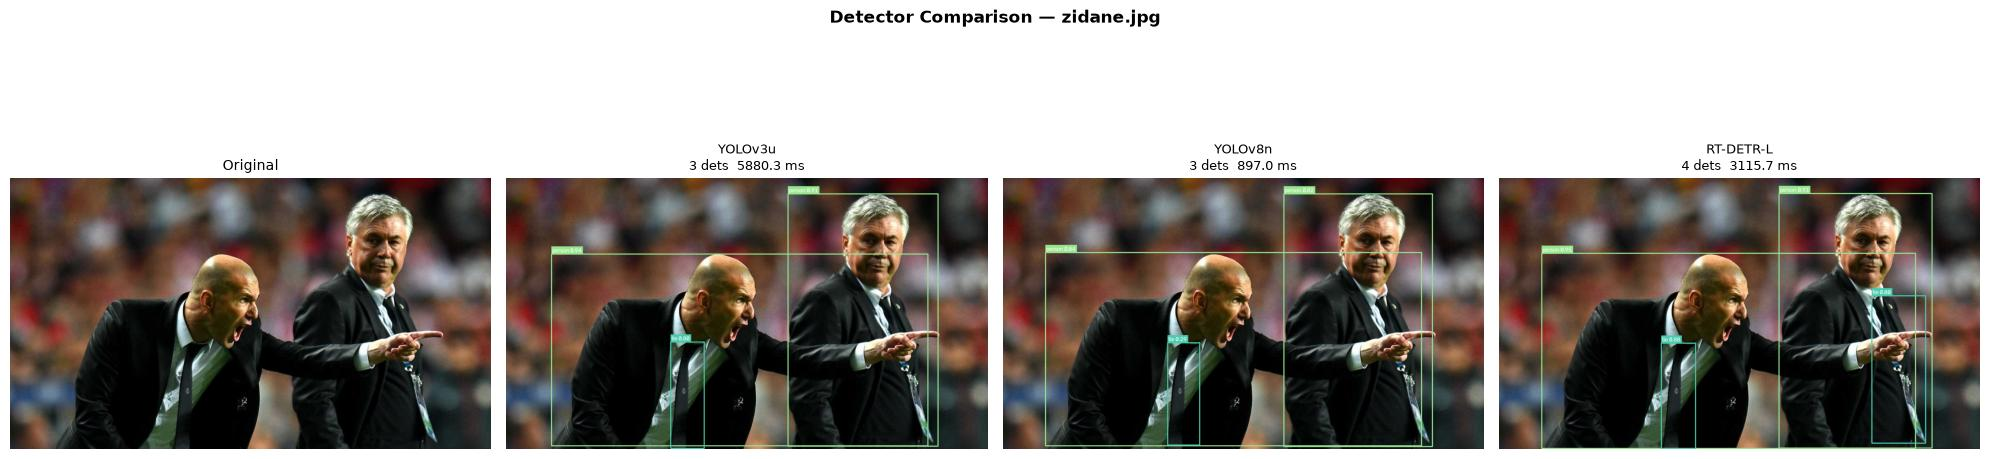

Saved → outputs_q2/q2_comparison_zidane_jpg.png


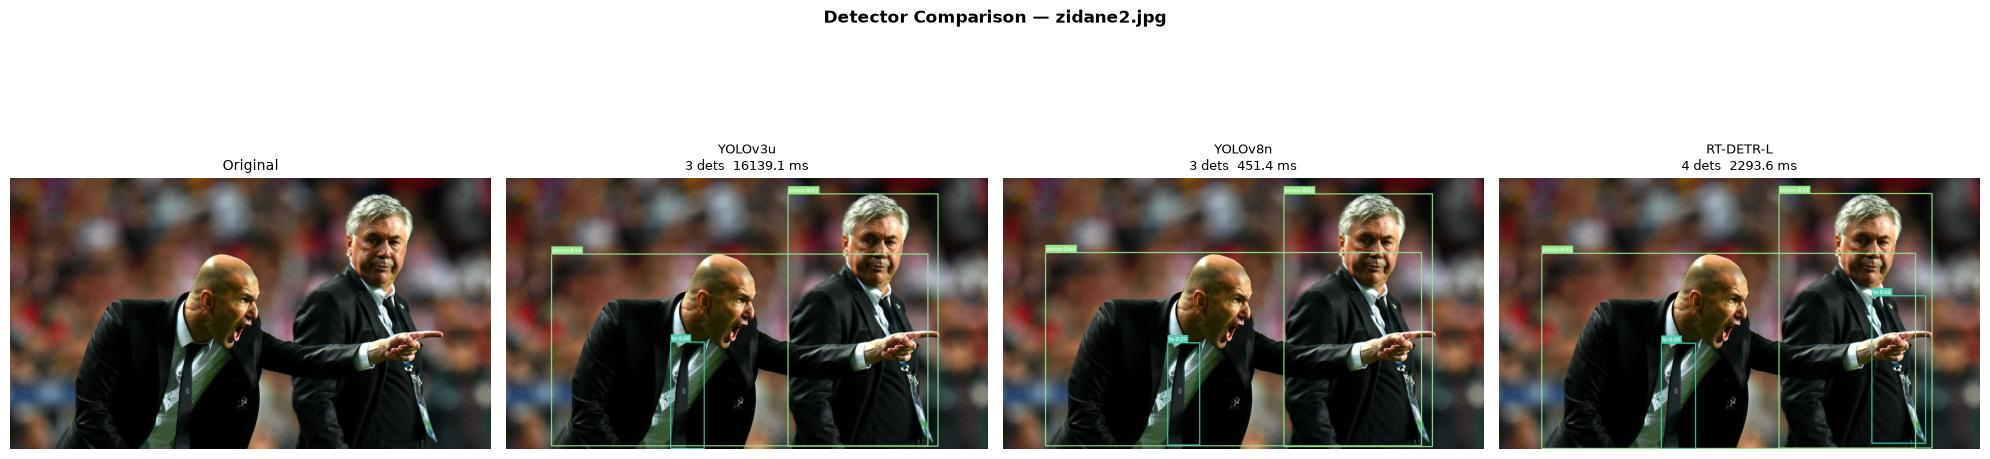

Saved → outputs_q2/q2_comparison_zidane2_jpg.png


In [9]:
model_names = list(models.keys())
img_names   = [p.name for p in IMAGES]

for img_name in img_names:
    fig, axes = plt.subplots(1, len(model_names)+1, figsize=(5*(len(model_names)+1), 6))

    # original
    axes[0].imshow(results_table[model_names[0]][img_name]["original"])
    axes[0].set_title("Original", fontsize=10)
    axes[0].axis("off")

    # each model
    for ax, mname in zip(axes[1:], model_names):
        r = results_table[mname][img_name]
        ax.imshow(r["annotated"])
        ax.set_title(f"{mname}\n{len(r['dets'])} dets  {r['infer_ms']:.1f} ms",
                     fontsize=9)
        ax.axis("off")

    plt.suptitle(f"Detector Comparison — {img_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    out_name = f"q2_comparison_{img_name.replace('.','_')}.png"
    plt.savefig(OUT / out_name, dpi=85, bbox_inches="tight")
    plt.show()
    print(f"Saved → outputs_q2/{out_name}")

## 5 — Detection Tables per Model

In [10]:
for mname in model_names:
    print(f"\n{'='*68}")
    print(f"  {mname}")
    print(f"{'='*68}")
    print(f"  {'Image':<22} {'Object':<20} {'Confidence':>10} {'BBox'}")
    print(f"  {'-'*64}")
    for img_name in img_names:
        for d in results_table[mname][img_name]["dets"]:
            print(f"  {img_name:<22} {d['label']:<20} {d['conf']:>10.4f} {d['bbox']}")


  YOLOv3u
  Image                  Object               Confidence BBox
  ----------------------------------------------------------------
  bus.jpg                bus                      0.9530 (2, 231, 804, 739)
  bus.jpg                person                   0.9156 (667, 386, 809, 879)
  bus.jpg                person                   0.8995 (50, 397, 249, 906)
  bus.jpg                person                   0.8799 (223, 405, 344, 860)
  bus.jpg                person                   0.5068 (0, 550, 79, 868)
  bus.jpg                fire hydrant             0.2899 (656, 625, 688, 713)
  bus2.jpg               bus                      0.9530 (2, 231, 804, 739)
  bus2.jpg               person                   0.9156 (667, 386, 809, 879)
  bus2.jpg               person                   0.8995 (50, 397, 249, 906)
  bus2.jpg               person                   0.8799 (223, 405, 344, 860)
  bus2.jpg               person                   0.5068 (0, 550, 79, 868)
  bus2.jpg    

## 6 — Confidence Score Distribution per Model

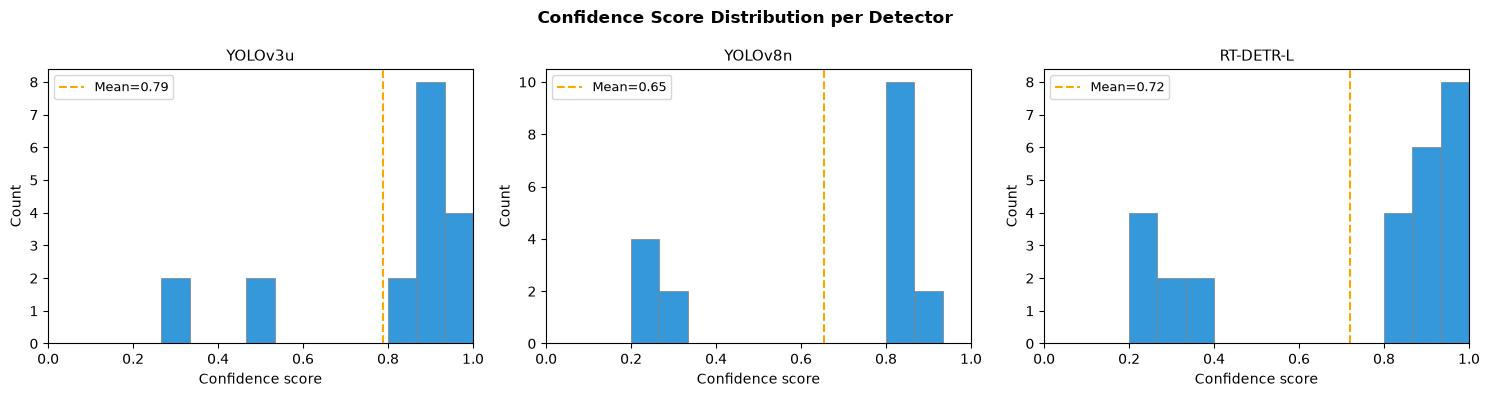

Saved → outputs_q2/q2_confidence_distributions.png


In [11]:
fig, axes = plt.subplots(1, len(model_names), figsize=(5*len(model_names), 4), sharey=False)
for ax, mname in zip(axes, model_names):
    all_confs = [d["conf"]
                 for img_name in img_names
                 for d in results_table[mname][img_name]["dets"]]
    if all_confs:
        ax.hist(all_confs, bins=15, range=(0,1), color="#3498db", edgecolor="grey", linewidth=0.5)
        ax.axvline(np.mean(all_confs), color="orange", linestyle="--",
                   label=f"Mean={np.mean(all_confs):.2f}")
        ax.legend(fontsize=9)
    ax.set_title(mname, fontsize=11)
    ax.set_xlabel("Confidence score")
    ax.set_ylabel("Count")
    ax.set_xlim(0, 1)

plt.suptitle("Confidence Score Distribution per Detector", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT / "q2_confidence_distributions.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → outputs_q2/q2_confidence_distributions.png")

## Summary

Each detector was run on the same images.
Bounding boxes, class labels, and confidence scores were drawn and compared.

Key observations:
- **YOLOv3u** is the classic anchor-based detector — tends toward more boxes with moderate confidence
- **YOLOv8n** is the modern anchor-free successor — typically fewer, more precise boxes
- **RT-DETR-L** (transformer) uses global attention — highest mean confidence but slowest